### Laboratorium 4, część 1: Detekcja obiektów metodami klasycznymi

#### _Fabuła_
_Aby nauczyć głęboki model do segmentacji_ amodalnej _(tj. odpornej na okluzje między obiektami) konieczne jest skonstruowanie odpowiednio anotowanego zbioru uczącego.
Pozyskanie takich danych w drodze manualnej anotacji jest zbyt kosztowne, dlatego obieramy podejście oparte o generowanie danych syntetycznych.
Dane generowane będą na podstawie zbioru_ modalnego, _tj. zawierającego wyłącznie nieprzysłonięte obiekty.
Obiekty te należy najpierw wysegmentować ze specjalnie przygotowanych obrazów źródłowych, a następnie przeanalizować ich kształty -- ten właśnie krok będzie Twoim zadaniem._

#### Zadania

Twoim celem jest wykonanie detekcji i segmentacji _obiektów zainteresowania_ z podanych obrazów źródłowych.

W **pierwszej kolejności** przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający kolekcję obiektów opisanych (1) prostokątem otaczającym (_bounding box_) - na potrzeby detekcji, oraz (2) maską binarną **lub** konturem (tj. zbiorem koordynat punktów brzegowych).
Potok przetwarzania powinien obejmować binaryzację obrazu kolorowego (znanymi Ci już metodami), detekcję komponentów spójności ([`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0)), oraz analizę blobów binarnych (obiektów).
Wykryte obiekty należy przefiltrować tak, aby pozostawić wyłącznie _obiekty zainteresowania_, tj. pojedyncze larwy.
Należy więc usunąć:
* drobne obiekty niebędące larwami,
* instancje złączone,
* wszelkie inne zakłócenia.

Zaimplementuj również funkcję pozwalającą na zaprezentowanie wyników detekcji w formie rysowania prostokątów odpowiadających instancjom oraz segmentacji w formie zaznaczania pikseli należących do instancji (może być w jednej funkcji z opcją wyboru).

**Następnie** opracujesz moduł przetwarzania poszczególnych instancji na poziomie masek binarnych lub konturów.
Moduł ten ma przyjmować pojedynczą instancję i wyznaczać dla niej podstawowe informacje, takie jak:
* długość (skorzystaj z [`skimage.morphology.skeletonize`](https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.skeletonize)) - relatywnie łatwa do _estymacji_, ale dość trudna do precyzyjnego _pomiaru_,
* grubość - może stanowić wyzwanie,
* klasyfikację kształtu (I-kształtne, S-kształtne, C-kształtne) -- potencjalnie trudne zadanie,
* ...

Nie musisz implementować ich wszystkich: na maksymalną ocenę wystarczą dwie miary zrobione _nieźle_ lub jedna opracowana _solidnie_.

#### Oczekiwane rezultaty
1. Zaprojektowanie potoku przetwarzania do detekcji i segmentacji - skonstruuj go najlepiej jako pojedynczą funkcję, ale pozostaw ślad z dokonywanych po drodze eksperymentów, tak aby możliwe było przeanalizowanie przebiegu operacji krok po kroku.
2. Zadbaj o możliwość przetworzenia tylko wybranego RoI z obrazu, aby można było przyjrzeć się "z bliska" wybranym rejonom (np. trudniejszym) -- rekomenduję zacząć pracę od wybrania mniejszego, wygodniejszego w przetwarzaniu rejonu.
3. Działanie modułu analizy zademonstruj na kilku wybranych przykładach, także umożliwiając podgląd operacji krok po kroku.
4. Debugging - jeśli na którymkolwiek etapie pojawią się problemy, których nie potrafisz rozwiązać, postaraj się przynajmniej przeanalizować, co je powoduje.

#### Literatura
1. [`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0), [OpenCV Structural Analysis and Shape Descriptors](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html), [OpenCV Drawing Functions](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html)
2. Publikacja, której częścią był potok przetwarzania podobny do tego, który zaimplementujesz: https://ieeexplore.ieee.org/document/10924163

In [1]:
from typing import List

import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage.morphology as skm

In [2]:
# staraj się projektować potok przetwarzania na jednym obrazie, a następnie przetestować go na drugim
calib = cv2.imread('proc_20221213112112426_image0.jpg')
test = cv2.imread('proc_20221213112219030_image0.jpg')

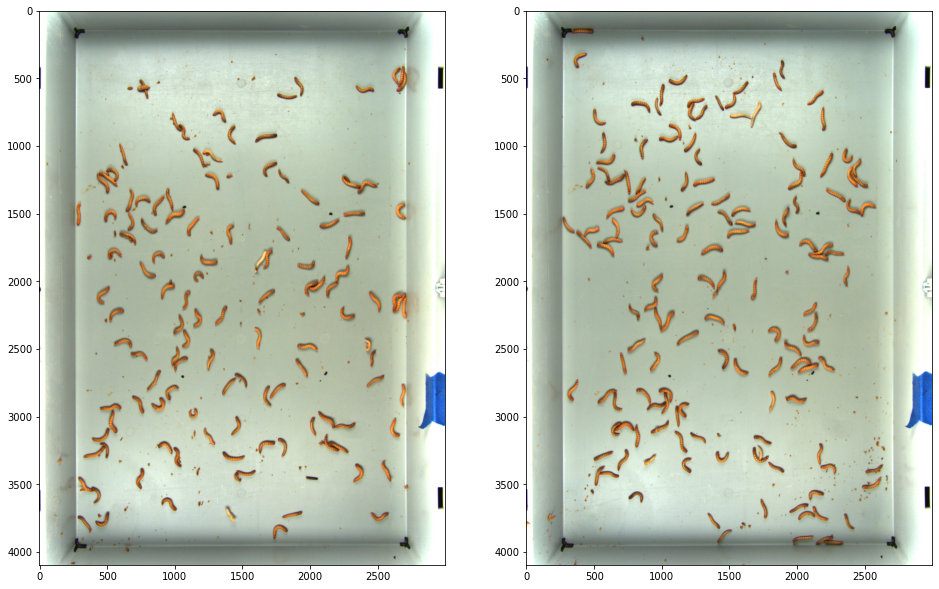

In [3]:
f, (a1, a2) = plt.subplots(1,2,figsize=(16,12))
a1.imshow(calib[...,::-1].transpose((1,0,2)))
a2.imshow(test[...,::-1].transpose((1,0,2)))

In [ ]:
def detect_objects(image: np.ndarray, **kwargs) -> List:
    # TU BĘDZIE TWOJA IMPLEMENTACJA DETEKTORA
    raise NotImplementedError

def analyze_objects(intances: List, **kwargs) -> List:
    # TU BĘDZIE TWOJA IMPLEMENTACJA ANALIZY OBIEKTÓW
    raise NotImplementedError

def display_objects(image: np.ndarray, objects: List) -> None:
    # TU BĘDZIE TWOJA IMPLEMENTACJA METODY WIZUALIZACJI
    raise NotImplementedError
